# Sección 5.5 — Modelos cinéticos de producción de cis-zeatina

Notebook reproducible para el análisis cinético de producción de **cis-zeatina**.

Incluye Luedeking–Piret, Bajpai–Reuss, Gaussiano Doble, comparación de métricas,
bootstrap paramétrico del Gaussiano Doble y exploración del *switch* de pH.

> Las concentraciones de cis-zeatina se expresan en **mg/L**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from sklearn.metrics import r2_score, mean_squared_error

np.set_printoptions(precision=8, suppress=True)
pd.set_option("display.precision", 8)

## 1. Datos experimentales

In [2]:
t_X = np.array([0,6,12,18,24,30,36,42,48,54,60,66,72,78,84,90,96,102], dtype=float)

X = np.array([
    0.0059,0.0059,0.034,0.034,0.145,0.145,0.601,0.601,
    1.377,1.377,3.203,3.203,4.104,4.280,3.959,4.219,4.219,4.219
], dtype=float)

pH_t = np.array([
    5.70,5.62,5.62,4.80,4.22,3.50,2.88,2.60,
    2.40,2.20,2.06,2.10,2.15,2.14,2.18,2.14,2.14,2.14
], dtype=float)

t_P = np.array([0,12,24,36,48,60,72,84,96], dtype=float)

P = np.array([
    0.00000,0.08808,0.10395,0.01175,0.03019,
    0.18280,0.15532,0.08044,0.04960
], dtype=float)

P_sd = np.array([
    0.00000,0.01914,0.04994,0.00566,0.01843,
    0.02406,0.00645,0.02861,0.05930
], dtype=float)

S = np.array([
    20.808,19.527,18.279,17.358,16.326,
    15.650,15.209,14.621,11.957
], dtype=float)

## 2. Métricas

In [3]:
def metricas(y_obs, y_pred):
    r2 = r2_score(y_obs, y_pred)
    rmse = np.sqrt(mean_squared_error(y_obs, y_pred))
    return r2, rmse

## 3. Gaussiano Doble

In [4]:
def gaussiano_doble(t, A1, mu1, sigma1, A2, mu2, sigma2):
    t = np.asarray(t, dtype=float)
    return (
        A1*np.exp(-((t-mu1)**2)/(2*sigma1**2))
        + A2*np.exp(-((t-mu2)**2)/(2*sigma2**2))
    )

p0_GD = [0.12, 20, 7, 0.18, 68, 12]
bounds_GD = (
    [0.0, 5.0, 1.0, 0.0, 45.0, 1.0],
    [1.0, 35.0, 30.0, 1.0, 95.0, 40.0]
)

popt_GD, pcov_GD = curve_fit(
    gaussiano_doble, t_P, P,
    p0=p0_GD, bounds=bounds_GD, maxfev=200000
)

P_GD = gaussiano_doble(t_P, *popt_GD)
r2_GD, rmse_GD = metricas(P, P_GD)

print(f"R² GD   = {r2_GD:.6f}")
print(f"RMSE GD = {rmse_GD:.6f} mg/L")

nombres_GD = ["A1 (mg/L)","μ1 (h)","σ1 (h)","A2 (mg/L)","μ2 (h)","σ2 (h)"]
display(pd.DataFrame({"Parámetro":nombres_GD,"Valor ajustado":popt_GD}))

R² GD   = 0.903875
RMSE GD = 0.018286 mg/L


,Parámetro,Valor ajustado
0,A1 (mg/L),0.15983429
1,μ1 (h),18.47186302
2,σ1 (h),5.92447759
3,A2 (mg/L),0.18464359
4,μ2 (h),67.49953534
5,σ2 (h),12.80297430


## 4. Luedeking–Piret

In [5]:
X_interp = interp1d(t_X, X, kind="linear", fill_value="extrapolate")
P0 = float(P[0])
X0 = float(X_interp(t_P[0]))

def integral_X_hasta(ti, ngrid=600):
    if np.isclose(ti, 0):
        return 0.0
    grid = np.linspace(0.0, float(ti), ngrid)
    return np.trapezoid(X_interp(grid), grid)

def LP_integrado(t, alpha, beta):
    t = np.asarray(t, dtype=float)
    ints = np.array([integral_X_hasta(ti) for ti in t])
    return P0 + alpha*(X_interp(t)-X0) + beta*ints

popt_LP, _ = curve_fit(LP_integrado, t_P, P, p0=[0.01,0.0001], maxfev=200000)
P_LP = LP_integrado(t_P, *popt_LP)
r2_LP, rmse_LP = metricas(P, P_LP)

print(f"R² LP   = {r2_LP:.6f}")
print(f"RMSE LP = {rmse_LP:.6f} mg/L")

R² LP   = 0.374997
RMSE LP = 0.046628 mg/L


## 5. Bajpai–Reuss

In [6]:
X_fun = interp1d(t_X, X, kind="linear", fill_value="extrapolate")
S_fun = interp1d(t_P, S, kind="linear", fill_value="extrapolate")

def simular_BR(t_eval, qmax, Kp, kd):
    t_eval = np.asarray(t_eval, dtype=float)
    order = np.argsort(t_eval)
    ts = t_eval[order]

    def ode(t, y):
        Pt = float(y[0])
        Xt = float(X_fun(t))
        St = float(S_fun(t))
        return [qmax*(St/(Kp+St))*Xt - kd*Pt]

    sol = solve_ivp(
        ode, (0.0, float(ts.max())), [P0],
        t_eval=ts, method="LSODA", rtol=1e-8, atol=1e-10
    )

    y_sorted = sol.y[0]
    y = np.empty_like(y_sorted)
    y[order] = y_sorted
    return y

def BR_curve_fit(t, qmax, Kp, kd):
    return simular_BR(t, qmax, Kp, kd)

popt_BR, _ = curve_fit(
    BR_curve_fit, t_P, P,
    p0=[0.001,5.0,0.01],
    bounds=([0.0,1e-6,0.0],[1.0,1000.0,1.0]),
    maxfev=200000
)

P_BR = BR_curve_fit(t_P, *popt_BR)
r2_BR, rmse_BR = metricas(P, P_BR)

print(f"R² BR   = {r2_BR:.6f}")
print(f"RMSE BR = {rmse_BR:.6f} mg/L")

R² BR   = -0.172320
RMSE BR = 0.063860 mg/L


## 6. Comparación de modelos

In [7]:
tabla_modelos = pd.DataFrame({
    "Modelo":["Luedeking–Piret","Bajpai–Reuss","Gaussiano Doble"],
    "K":[2,3,6],
    "R²":[r2_LP,r2_BR,r2_GD],
    "RMSE (mg/L)":[rmse_LP,rmse_BR,rmse_GD]
})
display(tabla_modelos)

,Modelo,K,R²,RMSE (mg/L)
0,Luedeking–Piret,2,0.37499705,0.04662792
1,Bajpai–Reuss,3,-0.17232019,0.06385989
2,Gaussiano Doble,6,0.90387481,0.01828621


## 7. Figura de comparación

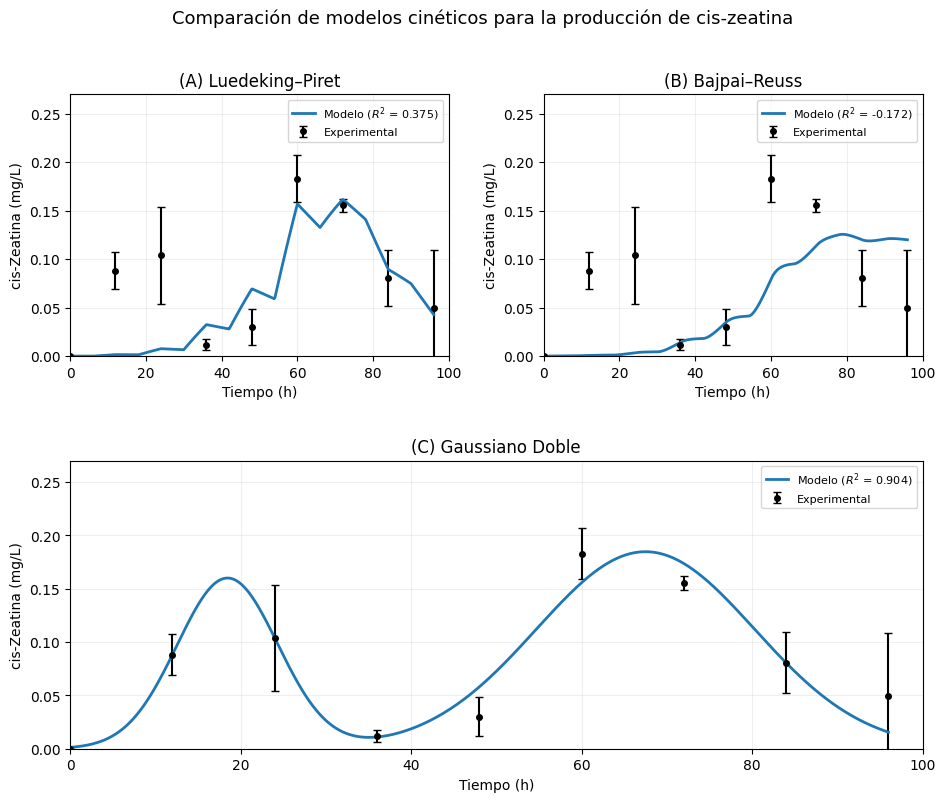

In [8]:
t_plot = np.linspace(0,96,500)
P_LP_plot = LP_integrado(t_plot, *popt_LP)
P_BR_plot = BR_curve_fit(t_plot, *popt_BR)
P_GD_plot = gaussiano_doble(t_plot, *popt_GD)

fig = plt.figure(figsize=(11,8.5))
gs = fig.add_gridspec(2,2,height_ratios=[1,1.1],hspace=0.38,wspace=0.25)

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1], sharey=ax1)
ax3 = fig.add_subplot(gs[1,:])

def graficar(ax, titulo, pred, r2):
    ax.errorbar(t_P,P,yerr=P_sd,fmt="o",color="black",markersize=4,capsize=3,label="Experimental")
    ax.plot(t_plot,pred,lw=2,label=f"Modelo ($R^2$ = {r2:.3f})")
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (h)")
    ax.set_ylabel("cis-Zeatina (mg/L)")
    ax.set_xlim(0,100)
    ax.set_ylim(0,0.27)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

graficar(ax1,"(A) Luedeking–Piret",P_LP_plot,r2_LP)
graficar(ax2,"(B) Bajpai–Reuss",P_BR_plot,r2_BR)
graficar(ax3,"(C) Gaussiano Doble",P_GD_plot,r2_GD)

fig.suptitle("Comparación de modelos cinéticos para la producción de cis-zeatina",fontsize=13,y=0.98)
plt.savefig("Figura_5_3_Modelos_Cineticos.png",dpi=300,bbox_inches="tight")
plt.show()

## 8. Bootstrap paramétrico del Gaussiano Doble

In [9]:
from tqdm.auto import tqdm

N_BOOT = 2000
rng = np.random.default_rng(42)
P_ajustado = gaussiano_doble(t_P, *popt_GD)

parametros_boot = []
fallos = 0

for _ in tqdm(range(N_BOOT), desc="Bootstrap"):
    P_sim = P_ajustado + rng.normal(0.0, P_sd, size=len(P))
    try:
        popt_b, _ = curve_fit(
            gaussiano_doble, t_P, P_sim,
            p0=popt_GD, bounds=bounds_GD, maxfev=200000
        )
        parametros_boot.append(popt_b)
    except (RuntimeError, ValueError):
        fallos += 1

parametros_boot = np.asarray(parametros_boot)

ic_inf = np.percentile(parametros_boot,2.5,axis=0)
ic_sup = np.percentile(parametros_boot,97.5,axis=0)
media_boot = np.mean(parametros_boot,axis=0)
sd_boot = np.std(parametros_boot,axis=0,ddof=1)
cv_boot = 100*sd_boot/np.abs(media_boot)

tabla_bootstrap = pd.DataFrame({
    "Parámetro":nombres_GD,
    "Valor ajustado":popt_GD,
    "IC 95% inferior":ic_inf,
    "IC 95% superior":ic_sup,
    "CV (%)":cv_boot
})
display(tabla_bootstrap)
print("Fallos:", fallos)

Bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,Parámetro,Valor ajustado,IC 95% inferior,IC 95% superior,CV (%)
0,A1 (mg/L),0.15983429,0.07998686,0.91767972,77.11768960
1,μ1 (h),18.47186302,12.86793202,20.89722749,10.39471549
2,σ1 (h),5.92447759,2.89055522,7.58793487,32.46476884
3,A2 (mg/L),0.18464359,0.15060899,0.21896139,9.33550341
4,μ2 (h),67.49953534,64.75758502,74.60583534,3.88265036
5,σ2 (h),12.80297430,9.66853870,20.78016008,21.99241699


Fallos: 0


## 9. Exploración del switch de pH

In [10]:
def pH_interp(t_arr):
    return np.interp(t_arr, t_X, pH_t)

pH_crit = 2.50
k_sw = 5.0

def GD_switch_pH(t):
    t = np.asarray(t, dtype=float)
    A1,m1,s1,A2,m2,s2 = popt_GD
    phi = 1.0/(1.0 + np.exp(k_sw*(pH_interp(t)-pH_crit)))
    return (
        A1*np.exp(-((t-m1)**2)/(2*s1**2))
        + A2*np.exp(-((t-m2)**2)/(2*s2**2))*phi
    )

P_SW = GD_switch_pH(t_P)
r2_SW, rmse_SW = metricas(P, P_SW)

t_sw = np.linspace(0,102,800)
phi_sw = 1.0/(1.0 + np.exp(k_sw*(pH_interp(t_sw)-pH_crit)))
t_cross = t_sw[np.argmin(np.abs(pH_interp(t_sw)-pH_crit))]

print(f"R² switch = {r2_SW:.6f}")
print(f"RMSE switch = {rmse_SW:.6f} mg/L")
print(f"Cruce aproximado pH=2.5: {t_cross:.2f} h")

R² switch = 0.888380
RMSE switch = 0.019705 mg/L
Cruce aproximado pH=2.5: 44.94 h


## 10. Nota de interpretación

El Gaussiano Doble se utiliza como modelo empírico descriptivo.  
El bootstrap cuantifica incertidumbre paramétrica bajo los supuestos del remuestreo.  
El *switch* de pH se interpreta como una hipótesis exploratoria, no como prueba causal.